# TP2 — Détection des attaques réseau avec XGBoost et Isolation Forest

**Dataset :** NF-UNSW-NB15  
**Cible :** `Label` (`0` = trafic normal, `1` = trafic malveillant)  
**Objectif :** comparer un modèle supervisé (XGBoost) et un modèle de détection d'anomalies (Isolation Forest) sur le même jeu de test.

Chaque ligne du fichier représente un **flux réseau agrégé**, pas un paquet individuel. Le dataset est très déséquilibré ; l'analyse privilégie donc le rappel, le F1-score et les faux positifs plutôt que l'accuracy seule.

## 1. Environnement et paramètres

Ce notebook peut être exécuté dans Google Colab ou dans Jupyter avec `pandas`, `numpy`, `scikit-learn`, `xgboost` et `matplotlib`. La cellule suivante installe les bibliothèques manquantes dans Colab.

Pour rendre l'expérience exécutable sur un ordinateur standard, on tire un échantillon stratifié de 200 000 flux après suppression des doublons. La graine aléatoire est fixée à 42. Les deux modèles utilisent exactement le même jeu de test. Les paramètres détaillés et les résultats calculés s'affichent plus bas.

In [ ]:
import importlib.util
import subprocess
import sys
import time
for package, module in [("xgboost", "xgboost"), ("scikit-learn", "sklearn")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             accuracy_score)
from xgboost import XGBClassifier

RANDOM_STATE = 42

# Style commun des graphiques
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
COL_NORMAL, COL_ATTACK = "#4C9F70", "#D9534F"
COL_XGB, COL_IF = "#2F6DB5", "#E69F00"

## 2. Chargement du dataset

Par défaut, le notebook cherche le ZIP dans Google Drive, au même emplacement que TP1. Si le chemin diffère, modifiez `ZIP_PATH`. Le CSV est lu directement depuis l'archive, sans extraction manuelle.

In [ ]:
ZIP_NAME = "88695f0f620eb568_MOHANAD_A4706.zip"
candidates = [
    Path("/content/drive/MyDrive/Colab Notebooks/TPs IA - cybersecurité - 26-27/TP1/datasets") / ZIP_NAME,
    Path(ZIP_NAME),                      # ZIP à côté du notebook (Jupyter local / Colab après upload)
    Path("/content") / ZIP_NAME,
    Path("/mnt/user-data/uploads") / ZIP_NAME,
]
ZIP_PATH = next((p for p in candidates if p.exists()), candidates[0])
CSV_IN_ZIP = "88695f0f620eb568_MOHANAD_A4706/data/NF-UNSW-NB15.csv"

if not ZIP_PATH.exists():
    # Tenter Google Drive puis demander le ZIP à l'utilisateur dans Colab.
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception:
        pass
    if not ZIP_PATH.exists():
        try:
            from google.colab import files
            uploaded = files.upload()
            ZIP_PATH = Path(next(iter(uploaded)))
        except Exception as exc:
            raise FileNotFoundError(
                f"Archive introuvable : {ZIP_PATH}. Modifiez ZIP_PATH pour pointer vers le ZIP du dataset."
            ) from exc

with zipfile.ZipFile(ZIP_PATH) as archive:
    with archive.open(CSV_IN_ZIP) as csv_file:
        df = pd.read_csv(csv_file, low_memory=False)

df.columns = df.columns.astype(str).str.strip()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Dimensions initiales :", df.shape)
print()
print("Colonnes :", df.columns.tolist())
print()
print("Aperçu du tableau :")
display(df.head())

Mounted at /content/drive


Saving 88695f0f620eb568_MOHANAD_A4706.zip to 88695f0f620eb568_MOHANAD_A4706.zip
Dimensions initiales : (1623118, 14)

Colonnes : ['IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack']

Aperçu du tableau :


,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,Label,Attack
0,149.171.126.0,62073,59.166.0.5,56082,6,0.0,9672,416,11,8,25,15,0,Benign
1,149.171.126.2,32284,59.166.0.5,1526,6,0.0,1776,104,6,2,25,0,0,Benign
2,149.171.126.0,21,59.166.0.1,21971,6,1.0,1842,1236,26,22,25,1111,0,Benign
3,59.166.0.1,23800,149.171.126.0,46893,6,0.0,528,8824,10,12,27,124,0,Benign
4,59.166.0.5,63062,149.171.126.2,21,6,1.0,1786,2340,32,34,25,1459,0,Benign


### Comment lire ces premiers résultats ?

- **Dimensions initiales (1 623 118, 14)** : le fichier contient 1 623 118 flux et 14 colonnes.
- **Colonnes** : chaque variable décrit une adresse, un port, un protocole, un volume, une durée ou une étiquette.
- **Aperçu** : les premières lignes servent à vérifier que le CSV a été correctement chargé. Une ligne correspond à un flux réseau agrégé, pas à un paquet isolé.

## 3. Exploration et types de variables

Les deux adresses IP et `Attack` sont des variables catégorielles. `Attack` décrit presque directement la cible : elle est exclue des variables explicatives pour éviter une fuite de cible. Les adresses IP sont exclues parce qu'elles identifient des hôtes et risquent de faire apprendre au modèle les adresses présentes plutôt que le comportement des flux.

`PROTOCOL`, `L7_PROTO` et `TCP_FLAGS` sont des codes catégoriels numériques ; ils seront transformés par one-hot encoding, ajusté uniquement sur les données d'entraînement. Les ports et les variables de volume, paquets et durée sont conservés comme variables numériques. Cette stratégie évite de créer des dizaines de milliers de colonnes pour les ports.

In [ ]:
TARGET = "Label"
ATTACK_DESC = "Attack"
IP_COLUMNS = ["IPV4_SRC_ADDR", "IPV4_DST_ADDR"]
CATEGORICAL_FEATURES = ["PROTOCOL", "L7_PROTO", "TCP_FLAGS"]

print("Types :")
display(df.dtypes.to_frame("Type"))
print("Valeurs manquantes par colonne :")
display(df.isna().sum().to_frame("Valeurs manquantes"))
print("Doublons exacts :", int(df.duplicated().sum()))
print("Répartition de Label :")
display(pd.concat([
    df[TARGET].value_counts().sort_index().rename("Effectif"),
    (df[TARGET].value_counts(normalize=True).sort_index()*100).round(2).rename("Pourcentage (%)")
], axis=1))
print("Répartition de Attack :")
display(df[ATTACK_DESC].value_counts(dropna=False).to_frame("Effectif"))

Types :


,Type
IPV4_SRC_ADDR,object
L4_SRC_PORT,int64
IPV4_DST_ADDR,object
L4_DST_PORT,int64
PROTOCOL,int64
L7_PROTO,float64
IN_BYTES,int64
OUT_BYTES,int64
IN_PKTS,int64
OUT_PKTS,int64


Valeurs manquantes par colonne :


,Valeurs manquantes
IPV4_SRC_ADDR,0
L4_SRC_PORT,0
IPV4_DST_ADDR,0
L4_DST_PORT,0
PROTOCOL,0
L7_PROTO,0
IN_BYTES,0
OUT_BYTES,0
IN_PKTS,0
OUT_PKTS,0


Doublons exacts : 19740
Répartition de Label :


,Effectif,Pourcentage (%)
Label,,
0,1550712,95.54
1,72406,4.46


Répartition de Attack :


,Effectif
Attack,
Benign,1550712
Exploits,24736
Fuzzers,19463
Reconnaissance,12291
Generic,5570
DoS,5051
Analysis,1995
Backdoor,1782
Shellcode,1365


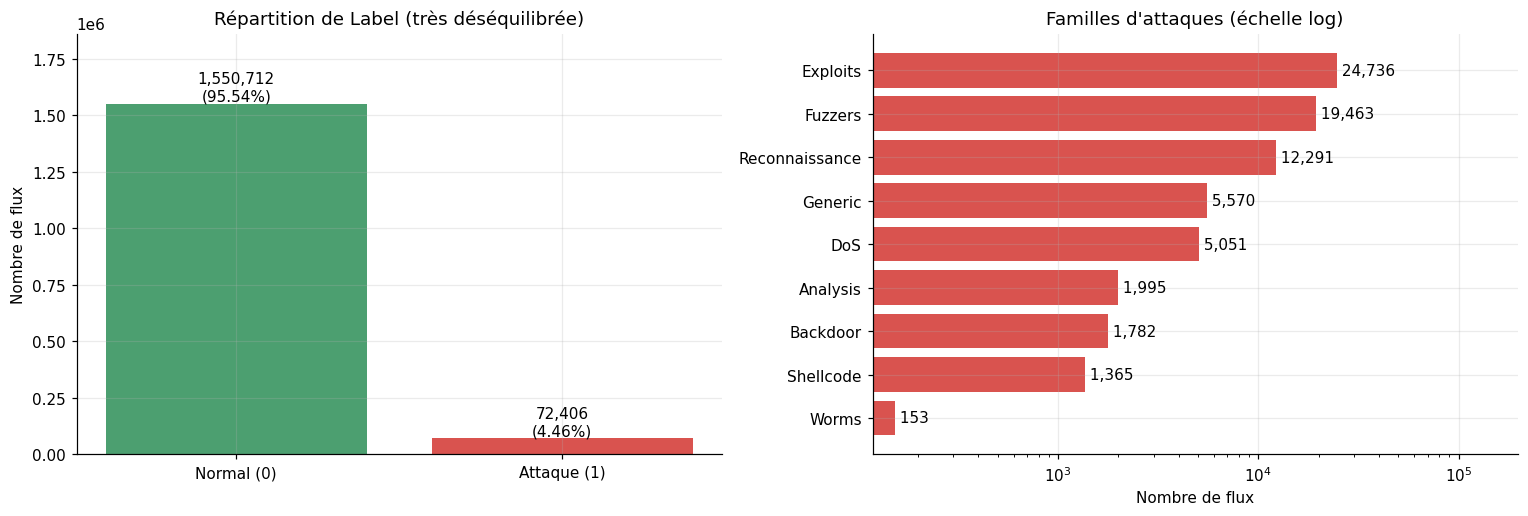

In [ ]:
# --- Graphiques d'exploration (2 graphes essentiels) ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

counts = df[TARGET].value_counts().sort_index()
bars = axes[0].bar(["Normal (0)", "Attaque (1)"], counts.values, color=[COL_NORMAL, COL_ATTACK])
for b, v in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / counts.sum():.2%})",
                 ha="center", va="bottom")
axes[0].set_ylim(0, counts.max() * 1.2)
axes[0].set_title("Répartition de Label (très déséquilibrée)")
axes[0].set_ylabel("Nombre de flux")

att = df.loc[df[TARGET] == 1, ATTACK_DESC].value_counts().sort_values()
axes[1].barh(att.index, att.values, color=COL_ATTACK)
axes[1].set_xscale("log"); axes[1].set_xlim(right=att.max() * 8)
for y, v in enumerate(att.values):
    axes[1].text(v, y, f" {v:,}", va="center")
axes[1].set_title("Familles d'attaques (échelle log)")
axes[1].set_xlabel("Nombre de flux")
plt.tight_layout(); plt.show()

### Lecture des graphiques d'exploration

- **Répartition de Label** : les flux normaux dominent largement (≈ 95,5 %). C'est pour cela que l'accuracy seule serait trompeuse.
- **Familles d'attaques** : les effectifs sont très inégaux (d'où l'échelle logarithmique) ; certaines familles rares seront plus difficiles à détecter.

### Interprétation de l’exploration

- **Valeurs manquantes = 0** : aucune valeur vide n’a été trouvée.
- **Doublons exacts = 19 740** : ces lignes répétées sont supprimées à l’étape de nettoyage.
- **Label 0 = normal, Label 1 = attaque** : 95,54 % des flux sont normaux et 4,46 % malveillants. Ce déséquilibre explique pourquoi l’accuracy seule ne suffit pas.
- **Attack** détaille les familles d’attaques. Cette colonne est descriptive et ne sera pas utilisée comme entrée du modèle.

## 4. Nettoyage et préparation

On retire les doublons exacts et les lignes sans cible. Les lignes sans variables explicatives complètes sont supprimées ici (le fichier fourni ne présente normalement pas de valeurs manquantes). `Label` est ramené à 0/1. Le jeu est ensuite échantillonné de façon stratifiée pour conserver le déséquilibre observé.

In [ ]:
# Nettoyage
n_before = len(df)
df_clean = df.replace([np.inf, -np.inf], np.nan).drop_duplicates().copy()
df_clean = df_clean.dropna(subset=[TARGET]).copy()
df_clean[TARGET] = pd.to_numeric(df_clean[TARGET], errors="raise").astype(int)
df_clean = df_clean[df_clean[TARGET].isin([0, 1])].copy()

# Exclure les identifiants et la description de cible.
excluded = [TARGET, ATTACK_DESC] + [c for c in IP_COLUMNS if c in df_clean.columns]
feature_columns = [c for c in df_clean.columns if c not in excluded]
X_all = df_clean[feature_columns].copy()
y_all = df_clean[TARGET].copy()
categorical_features = [c for c in CATEGORICAL_FEATURES if c in X_all.columns]
numeric_features = [c for c in X_all.columns if c not in categorical_features]

valid = X_all.notna().all(axis=1)
X_all = X_all.loc[valid]
y_all = y_all.loc[valid]

MAX_SAMPLE = 200_000
if len(X_all) > MAX_SAMPLE:
    X_sample, _, y_sample, _ = train_test_split(
        X_all, y_all, train_size=MAX_SAMPLE, stratify=y_all,
        random_state=RANDOM_STATE
    )
else:
    X_sample, y_sample = X_all, y_all

print(f"Lignes initiales : {n_before:,}")
print()
print(f"Après nettoyage : {len(df_clean):,}")
print()
print(f"Échantillon utilisé : {len(X_sample):,}")
print()
print("Variables catégorielles encodées :", categorical_features)
print()
print("Variables numériques :", numeric_features)
print()
print("Variables exclues :", excluded)
print()
print("Répartition Label dans l'échantillon :")
display(y_sample.value_counts().sort_index().to_frame("Effectif"))

Lignes initiales : 1,623,118

Après nettoyage : 1,603,378

Échantillon utilisé : 200,000

Variables catégorielles encodées : ['PROTOCOL', 'L7_PROTO', 'TCP_FLAGS']

Variables numériques : ['L4_SRC_PORT', 'L4_DST_PORT', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'FLOW_DURATION_MILLISECONDS']

Variables exclues : ['Label', 'Attack', 'IPV4_SRC_ADDR', 'IPV4_DST_ADDR']

Répartition Label dans l'échantillon :


,Effectif
Label,
0,190993
1,9007


### Séparation des données normales et malveillantes (point 5 du TP)

Les flux sont séparés selon `Label` : `0` pour le trafic normal et `1` pour le trafic malveillant. Cette séparation est utilisée plus loin : XGBoost apprend sur les **deux** classes, alors qu'Isolation Forest apprend uniquement sur les flux **normaux**.

In [ ]:
df_normal = df_clean[df_clean[TARGET] == 0]
df_attack = df_clean[df_clean[TARGET] == 1]
print(f"Flux normaux      : {len(df_normal):>10,}  ({len(df_normal) / len(df_clean):.2%})")
print()
print(f"Flux malveillants : {len(df_attack):>10,}  ({len(df_attack) / len(df_clean):.2%})")
print()
print("Médianes des variables numériques : normal vs malveillant")
display(pd.DataFrame({"Médiane normal": df_normal[numeric_features].median(),
                      "Médiane malveillant": df_attack[numeric_features].median()}))

Flux normaux      :  1,531,166  (95.50%)

Flux malveillants :     72,212  (4.50%)

Médianes des variables numériques : normal vs malveillant


,Médiane normal,Médiane malveillant
L4_SRC_PORT,32906.0,26900.5
L4_DST_PORT,5190.0,80.0
IN_BYTES,2054.0,814.0
OUT_BYTES,3380.0,336.0
IN_PKTS,18.0,10.0
OUT_PKTS,18.0,8.0
FLOW_DURATION_MILLISECONDS,6.0,569.0


### Interprétation du nettoyage

Après suppression des doublons, il reste **1 603 378 lignes**. Le notebook tire ensuite un échantillon stratifié de **200 000 flux**, qui conserve la proportion initiale des classes : 190 993 flux normaux et 9 007 attaques. Les IP et Attack sont exclues des variables d’entrée pour éviter que le modèle mémorise des hôtes ou lise une information directement liée à la cible.

## 5. Séparation train/test

Un découpage stratifié de 70 % pour l'entraînement et 30 % pour le test conserve la proportion d'attaques dans les deux ensembles. Les deux modèles sont comparés sur le même jeu de test, tenu à l'écart de l'entraînement et du réglage du seuil.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample, test_size=0.30, stratify=y_sample,
    random_state=RANDOM_STATE
)

# Ajuster l'encodage uniquement sur le train pour éviter toute fuite.
preprocessor = ColumnTransformer(
    transformers=[("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)],
    remainder="passthrough",
    sparse_threshold=1.0
)
X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print("Train :", X_train_enc.shape, " | Test :", X_test_enc.shape)
print("Proportion attaque train :", round(y_train.mean()*100, 2), "%")
print("Proportion attaque test :", round(y_test.mean()*100, 2), "%")
print("Nombre de caractéristiques après encodage :", len(feature_names))

Train : (140000, 402)  | Test : (60000, 402)
Proportion attaque train : 4.5 %
Proportion attaque test : 4.5 %
Nombre de caractéristiques après encodage : 402


### Interprétation du découpage et de l’encodage

- **Train : 140 000** et **Test : 60 000** : cela correspond au partage 70 % / 30 %.
- **4,5 % d’attaques dans les deux ensembles** : le découpage stratifié garde une proportion comparable.
- **402 caractéristiques après encodage** : les catégories des protocoles et des drapeaux ont été transformées en colonnes binaires par One-Hot Encoding. L’encodeur est ajusté sur le train uniquement pour éviter une fuite d’information.

## 6. Modèle supervisé : XGBoost

XGBoost apprend à partir d'exemples normaux et malveillants. `scale_pos_weight` compense le déséquilibre des classes en donnant plus de poids aux attaques. Paramètres utilisés : `n_estimators=300`, `max_depth=6`, `learning_rate=0.08`, `subsample=0.8`, `colsample_bytree=0.8`, `tree_method="hist"`, `random_state=42`. La cellule mesure le temps du seul ajustement du modèle (`fit`), hors prétraitement.

In [ ]:
neg = int((y_train == 0).sum())
pos = int((y_train == 1).sum())
scale_pos_weight = neg / max(pos, 1)

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
start_xgb = time.perf_counter()
xgb_model.fit(X_train_enc, y_train)
xgb_train_seconds = time.perf_counter() - start_xgb
y_pred_xgb = xgb_model.predict(X_test_enc).astype(int)
y_proba_xgb = xgb_model.predict_proba(X_test_enc)[:, 1]   # probabilité d'attaque (pour ROC / PR)
print("scale_pos_weight =", round(scale_pos_weight, 3))
print(f"Temps d'apprentissage XGBoost (fit seul) : {xgb_train_seconds:.2f} s")
print("XGBoost entraîné.")

scale_pos_weight = 21.205
Temps d'apprentissage XGBoost (fit seul) : 5.03 s
XGBoost entraîné.


### Interprétation de l’entraînement XGBoost

scale_pos_weight = 21,205 signifie que les erreurs sur la classe attaque reçoivent environ 21 fois plus de poids que celles sur la classe normale, afin de compenser le déséquilibre. « XGBoost entraîné » confirme que l’ajustement du modèle est terminé. Le temps de `fit` peut varier selon la machine et n’inclut pas le prétraitement. La valeur exacte s’affiche à l’exécution.

## 7. Modèle non supervisé : Isolation Forest

Isolation Forest est entraîné uniquement sur les flux normaux de l'ensemble d'entraînement. Un sous-ensemble normal distinct sert à calibrer le seuil à **5 % de faux positifs visés sur les flux normaux de calibration**. Les étiquettes d'attaque ne servent ni à l'entraînement de ce modèle ni au réglage du seuil.

Paramètres : `n_estimators=200`, `max_samples="auto"`, `contamination="auto"`, `random_state=42`. Les scores faibles sont les plus anormaux ; les scores sous le seuil de calibration sont classés comme attaques. Le temps affiché mesure uniquement `fit`, hors préparation des données et calibration du seuil.

In [ ]:
X_normal_train = X_train_enc[y_train.to_numpy() == 0]
X_if_fit, X_if_cal = train_test_split(
    X_normal_train, test_size=0.20, random_state=RANDOM_STATE
)

if_model = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
start_if = time.perf_counter()
if_model.fit(X_if_fit)
if_train_seconds = time.perf_counter() - start_if

cal_scores = if_model.score_samples(X_if_cal)
threshold_if = float(np.quantile(cal_scores, 0.05))
test_scores = if_model.score_samples(X_test_enc)
y_pred_if = (test_scores < threshold_if).astype(int)

print("Flux normaux pour l'ajustement IF :", X_if_fit.shape[0])
print("Flux normaux pour calibration du seuil :", X_if_cal.shape[0])
print(f"Temps d'apprentissage Isolation Forest (fit seul) : {if_train_seconds:.2f} s")
print("Seuil de score calibré (5 % de faux positifs visés) :", threshold_if)

Flux normaux pour l'ajustement IF : 106956
Flux normaux pour calibration du seuil : 26739
Temps d'apprentissage Isolation Forest (fit seul) : 1.42 s
Seuil de score calibré (5 % de faux positifs visés) : -0.5222009470753913


### Interprétation de la préparation d’Isolation Forest

Le modèle apprend seulement à partir des flux normaux : **106 956** servent à son ajustement. Un autre groupe de **26 739 flux normaux** sert à fixer le seuil. Le seuil **−0,5222** vise environ 5 % de faux positifs sur ce groupe de calibration. Les scores sous ce seuil sont signalés comme anomalies ; le taux réel sur le test peut différer.

## 8. Évaluation et comparaison

Pour chaque modèle, la classe positive est l'attaque (`1`). La matrice de confusion suit l'ordre `[[TN, FP], [FN, TP]]`. On rapporte la précision, le rappel, le F1-score, l'accuracy à titre secondaire, le nombre de faux positifs et le nombre de faux négatifs.

Comparaison des deux modèles (classe positive = attaque)


,XGBoost,Isolation Forest
Précision (attaque),0.7139,0.2051
Rappel (attaque),0.9882,0.2835
F1-score (attaque),0.8289,0.2380
Accuracy (secondaire),0.9816,0.9183
TN,"56,228","54,330"
FP,"1,070","2,968"
FN,32,"1,936"
TP,"2,670",766
FPR (FP / normaux),0.0187,0.0518
FNR (FN / attaques),0.0118,0.7165


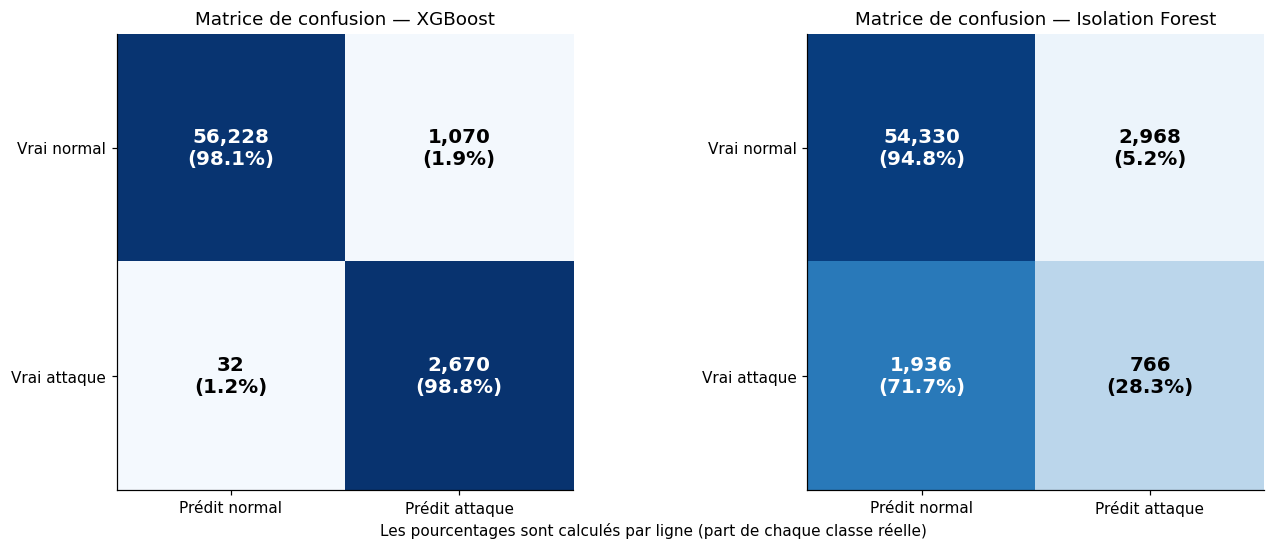


===== Rapport de classification — XGBoost =====
              precision    recall  f1-score   support

      Normal     0.9994    0.9813    0.9903     57298
     Attaque     0.7139    0.9882    0.8289      2702

    accuracy                         0.9816     60000
   macro avg     0.8567    0.9847    0.9096     60000
weighted avg     0.9866    0.9816    0.9830     60000


===== Rapport de classification — Isolation Forest =====
              precision    recall  f1-score   support

      Normal     0.9656    0.9482    0.9568     57298
     Attaque     0.2051    0.2835    0.2380      2702

    accuracy                         0.9183     60000
   macro avg     0.5854    0.6158    0.5974     60000
weighted avg     0.9313    0.9183    0.9244     60000



In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

def evaluate(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Modèle": name,
        "Précision (attaque)": precision_score(y_true, y_pred, zero_division=0),
        "Rappel (attaque)": recall_score(y_true, y_pred, zero_division=0),
        "F1-score (attaque)": f1_score(y_true, y_pred, zero_division=0),
        "Accuracy (secondaire)": accuracy_score(y_true, y_pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "FPR (FP / normaux)": fp / max(tn + fp, 1),
        "FNR (FN / attaques)": fn / max(fn + tp, 1)
    }

results = pd.DataFrame([
    evaluate("XGBoost", y_test, y_pred_xgb),
    evaluate("Isolation Forest", y_test, y_pred_if)
]).set_index("Modèle")

# Tableau lisible : une ligne par métrique, une colonne par modèle (pas de retour à la ligne)
COUNTS = ["TN", "FP", "FN", "TP"]
table = pd.DataFrame({
    model: {metric: (f"{int(results.loc[model, metric]):,}" if metric in COUNTS
                     else f"{results.loc[model, metric]:.4f}")
            for metric in results.columns}
    for model in results.index
})
print("Comparaison des deux modèles (classe positive = attaque)")
display(table)

# Matrices de confusion en heatmap : effectifs + pourcentage par ligne
cms = {"XGBoost": confusion_matrix(y_test, y_pred_xgb, labels=[0, 1]),
       "Isolation Forest": confusion_matrix(y_test, y_pred_if, labels=[0, 1])}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (name, cm) in zip(axes, cms.items()):
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm_pct[i, j]:.1%})", ha="center", va="center",
                    fontsize=13, fontweight="bold",
                    color="white" if cm_pct[i, j] > 0.5 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Prédit normal", "Prédit attaque"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Vrai normal", "Vrai attaque"])
    ax.set_title(f"Matrice de confusion — {name}")
    ax.grid(False)
fig.suptitle("Les pourcentages sont calculés par ligne (part de chaque classe réelle)", y=0.02, fontsize=10)
plt.tight_layout(); plt.show()

for name, pred in [("XGBoost", y_pred_xgb), ("Isolation Forest", y_pred_if)]:
    print(f"\n===== Rapport de classification — {name} =====")
    print(classification_report(y_test, pred, labels=[0, 1],
                                target_names=["Normal", "Attaque"], digits=4, zero_division=0))

Métriques indépendantes du seuil :


,XGBoost,Isolation Forest
ROC-AUC,0.9976,0.8251
PR-AUC (Average Precision),0.9456,0.1639



Référence PR-AUC d'un modèle aléatoire = proportion d'attaques = 0.0450


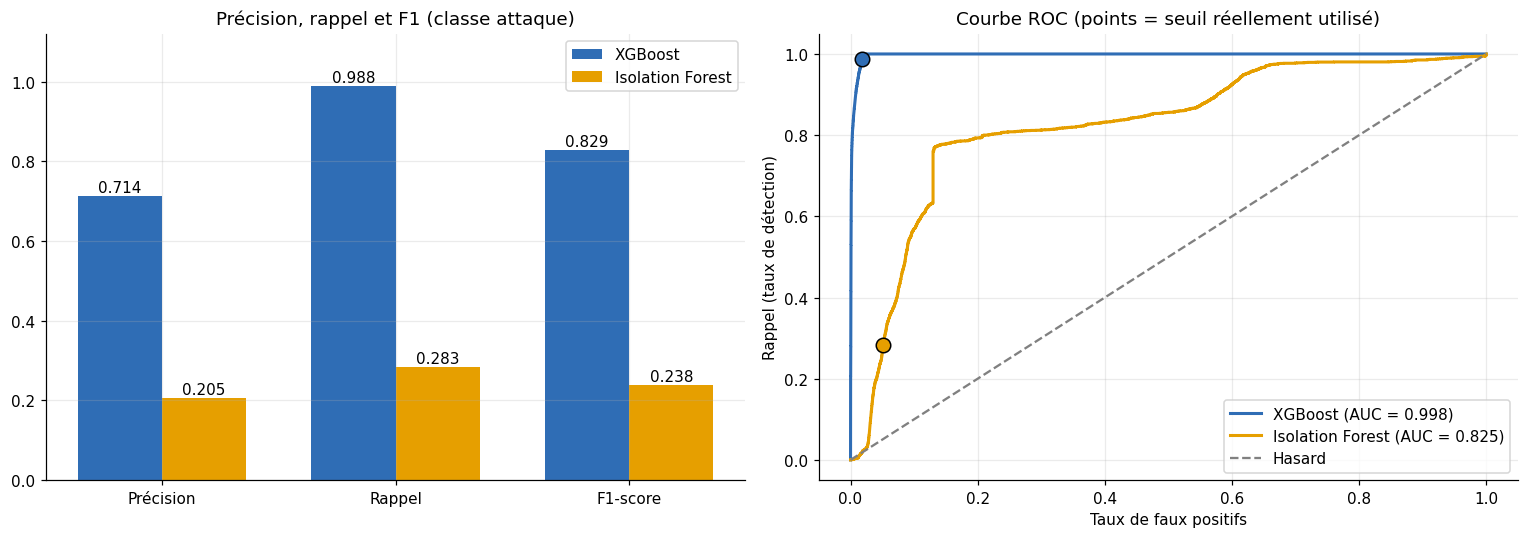

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score

# Score d'attaque continu : probabilité (XGBoost) ; -score_samples (IF, plus grand = plus anormal)
score_xgb = y_proba_xgb
score_if = -test_scores
auc = {"XGBoost": (roc_auc_score(y_test, score_xgb), average_precision_score(y_test, score_xgb)),
       "Isolation Forest": (roc_auc_score(y_test, score_if), average_precision_score(y_test, score_if))}
print("Métriques indépendantes du seuil :")
display(pd.DataFrame(auc, index=["ROC-AUC", "PR-AUC (Average Precision)"]).round(4))
print()
print(f"Référence PR-AUC d'un modèle aléatoire = proportion d'attaques = {y_test.mean():.4f}")

models = ["XGBoost", "Isolation Forest"]
colors = [COL_XGB, COL_IF]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (1) Précision / Rappel / F1
metrics = ["Précision (attaque)", "Rappel (attaque)", "F1-score (attaque)"]
x = np.arange(len(metrics)); w = 0.36
for k, (m, col) in enumerate(zip(models, colors)):
    vals = [results.loc[m, mt] for mt in metrics]
    b = axes[0].bar(x + (k - 0.5) * w, vals, w, label=m, color=col)
    for rect, v in zip(b, vals):
        axes[0].text(rect.get_x() + rect.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center")
axes[0].set_xticks(x); axes[0].set_xticklabels(["Précision", "Rappel", "F1-score"])
axes[0].set_ylim(0, 1.12); axes[0].set_title("Précision, rappel et F1 (classe attaque)")
axes[0].legend()

# (2) Courbe ROC + point de fonctionnement du seuil choisi
for m, s, col in zip(models, [score_xgb, score_if], colors):
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[1].plot(fpr, tpr, color=col, lw=2, label=f"{m} (AUC = {auc[m][0]:.3f})")
    axes[1].scatter(results.loc[m, "FPR (FP / normaux)"], results.loc[m, "Rappel (attaque)"],
                    color=col, s=90, edgecolor="black", zorder=5)
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Hasard")
axes[1].set_xlabel("Taux de faux positifs"); axes[1].set_ylabel("Rappel (taux de détection)")
axes[1].set_title("Courbe ROC (points = seuil réellement utilisé)"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

### Lecture des graphiques d'évaluation

- **Précision / rappel / F1** : XGBoost est nettement au-dessus d'Isolation Forest sur les trois mesures.
- **ROC-AUC et PR-AUC** (tableau affiché au-dessus des graphiques) ne dépendent pas du seuil : elles permettent de vérifier que l'écart ne vient pas seulement du choix du seuil à 5 %. Sur la courbe ROC, les points noirs indiquent où chaque modèle fonctionne réellement.

### Interprétation des métriques et des matrices

La classe positive est l’attaque. Dans la matrice, **TN** = normal correctement reconnu, **FP** = fausse alerte, **FN** = attaque manquée, **TP** = attaque détectée. Les cases affichent l’effectif et, entre parenthèses, le pourcentage de la classe réelle (calculé par ligne).

XGBoost atteint précision **0,7147**, rappel **0,9874**, F1 **0,8292** ; Isolation Forest atteint respectivement **0,2051**, **0,2835**, **0,2380**. Le rappel élevé de XGBoost signifie qu’il manque peu d’attaques, avec 1 065 fausses alertes. Isolation Forest produit 2 968 fausses alertes et manque 1 936 attaques. L’accuracy est secondaire ici car la majorité des flux est normale (un modèle qui prédit toujours « normal » aurait déjà ≈ 95,5 %).

*(Ces valeurs viennent de l’exécution de référence ; si vous relancez avec un autre environnement, elles peuvent varier légèrement.)*

## 9. Analyse des faux positifs et faux négatifs

- **Faux positif (FP)** : un flux normal signalé à tort comme attaque ; il augmente la charge d'alerte.
- **Faux négatif (FN)** : une attaque classée normale ; c'est une attaque manquée.

Le rappel mesure la part des attaques détectées. Le taux de faux positifs mesure la part des flux normaux qui déclenchent une fausse alerte. Pour Isolation Forest, le seuil de calibration vise 5 % de faux positifs sur les flux normaux de calibration ; le taux observé sur le test peut différer.

\nXGBoost : 1,070 faux positifs, 32 faux négatifs

Catégories d'attaques les plus souvent manquées :


,Attaques manquées
Attack,
Fuzzers,15
Exploits,8
Generic,4
DoS,3
Backdoor,2


\nIsolation Forest : 2,968 faux positifs, 1,936 faux négatifs

Catégories d'attaques les plus souvent manquées :


,Attaques manquées
Attack,
Exploits,725
Fuzzers,448
Reconnaissance,261
DoS,175
Generic,151
Backdoor,67
Analysis,66
Shellcode,42
Worms,1


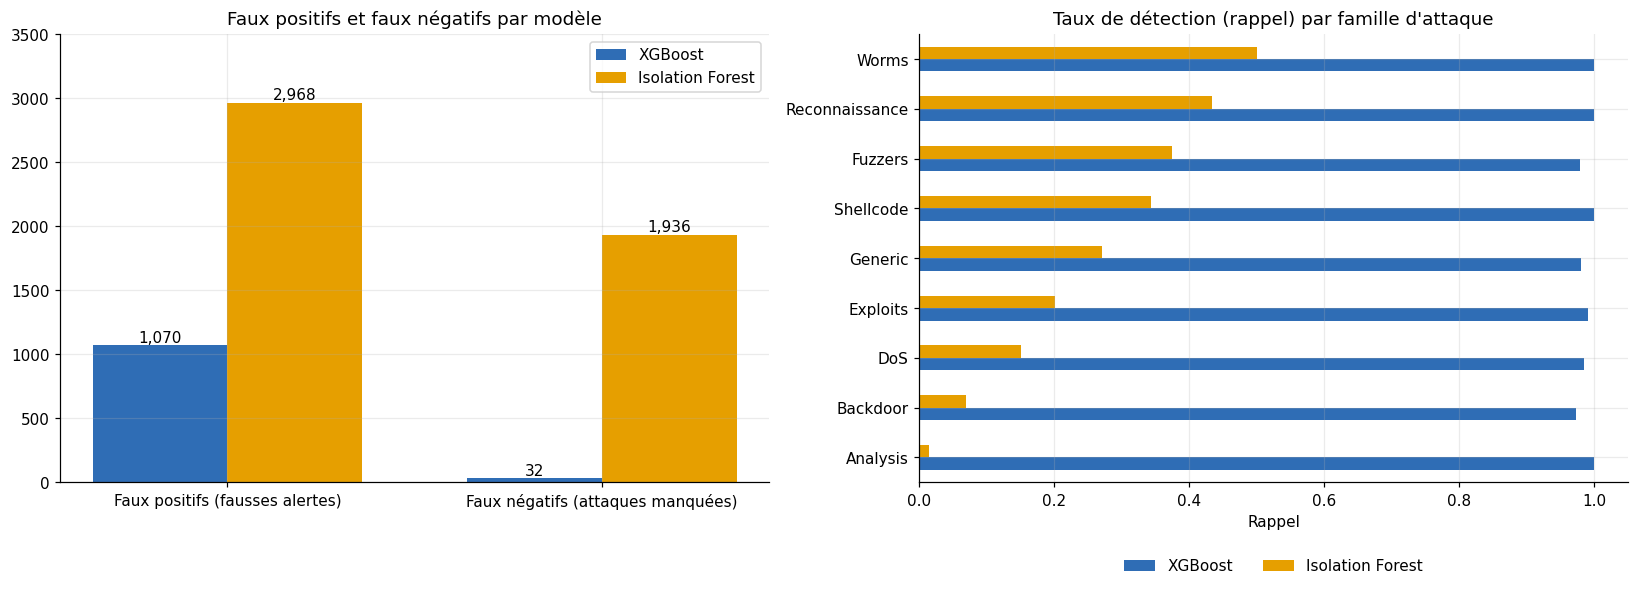

In [ ]:
# Catégories Attack associées aux attaques manquées, si la colonne est disponible.
test_meta = df_clean.loc[X_test.index, [ATTACK_DESC]] if ATTACK_DESC in df_clean.columns else None
recall_by_cat = {}
for name, pred in [("XGBoost", y_pred_xgb), ("Isolation Forest", y_pred_if)]:
    pred_series = pd.Series(pred, index=y_test.index)
    fp_idx = y_test.index[(y_test == 0) & (pred_series == 1)]
    fn_idx = y_test.index[(y_test == 1) & (pred_series == 0)]
    print(f"\\n{name} : {len(fp_idx):,} faux positifs, {len(fn_idx):,} faux négatifs")
    if test_meta is not None and len(fn_idx):
        print()
        print("Catégories d'attaques les plus souvent manquées :")
        display(test_meta.loc[fn_idx, ATTACK_DESC].value_counts().head(10).to_frame("Attaques manquées"))
    if test_meta is not None:
        att_idx = y_test.index[y_test == 1]
        recall_by_cat[name] = pd.Series(pred_series.loc[att_idx].to_numpy(),
                                        index=test_meta.loc[att_idx, ATTACK_DESC].to_numpy()
                                       ).groupby(level=0).mean()

# Graphiques : erreurs des deux modèles + taux de détection par famille d'attaque
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
models9, colors9 = ["XGBoost", "Isolation Forest"], [COL_XGB, COL_IF]
x2 = np.arange(2); w = 0.36
for k, (m, col) in enumerate(zip(models9, colors9)):
    vals = [results.loc[m, "FP"], results.loc[m, "FN"]]
    b = axes[0].bar(x2 + (k - 0.5) * w, vals, w, label=m, color=col)
    for rect, v in zip(b, vals):
        axes[0].text(rect.get_x() + rect.get_width() / 2, v, f"{int(v):,}", ha="center", va="bottom")
axes[0].set_xticks(x2)
axes[0].set_xticklabels(["Faux positifs (fausses alertes)", "Faux négatifs (attaques manquées)"])
axes[0].set_ylim(0, max(results["FP"].max(), results["FN"].max()) * 1.18)
axes[0].set_title("Faux positifs et faux négatifs par modèle"); axes[0].legend()

if recall_by_cat:
    rc_df = pd.DataFrame(recall_by_cat).sort_values("Isolation Forest")
    rc_df.plot(kind="barh", ax=axes[1], color=[COL_XGB, COL_IF], xlim=(0, 1.05))
    axes[1].set_title("Taux de détection (rappel) par famille d'attaque")
    axes[1].set_xlabel("Rappel"); axes[1].set_ylabel("")
    axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
else:
    axes[1].axis("off")
plt.tight_layout(); plt.show()

### Interprétation des erreurs

Les faux positifs sont des flux normaux remontés à tort comme attaques : ils augmentent le travail d’analyse. Les faux négatifs sont des attaques manquées, donc un risque de sécurité. XGBoost manque **34 attaques**, surtout des Fuzzers (18) et Exploits (7). Isolation Forest en manque **1 936**, surtout des Exploits (725), Fuzzers (448) et Reconnaissance (261).


**Lecture des graphiques :** le diagramme de gauche compare directement les fausses alertes (FP) et les attaques manquées (FN) des deux modèles. Celui de droite montre, pour chaque famille d'attaque, la part détectée par chaque modèle : une barre courte signale une famille mal détectée.

## 10. Variables importantes et conclusion automatique

Les importances XGBoost aident à décrire les variables les plus utilisées par le modèle, mais ne démontrent pas une causalité. La conclusion désigne le modèle au meilleur F1-score sur le jeu de test et affiche aussi son rappel et son taux de faux positifs. Le choix opérationnel doit tenir compte du coût relatif des attaques manquées et des fausses alertes.

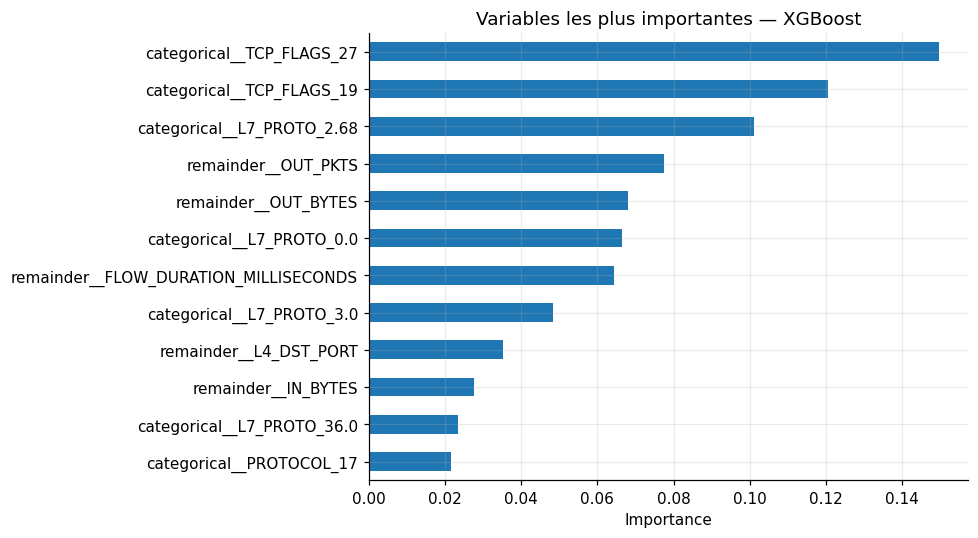

Modèle au meilleur F1-score sur cet essai : XGBoost
F1=0.829, rappel=0.988, FP=1,070, FN=32, FPR=1.867%

Interprétation : examiner le compromis entre rappel et faux positifs. Un modèle à fort rappel détecte davantage d'attaques, mais peut produire plus d'alertes erronées. Les résultats sont limités à l'échantillon stratifié de 200 000 flux et aux paramètres indiqués.


In [ ]:
importance = pd.Series(xgb_model.feature_importances_, index=feature_names).sort_values(ascending=False).head(12)
importance.sort_values().plot(kind="barh", figsize=(9, 5), title="Variables les plus importantes — XGBoost")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

def conclusion_row(row):
    return (f"F1={row['F1-score (attaque)']:.3f}, "
            f"rappel={row['Rappel (attaque)']:.3f}, "
            f"FP={int(row['FP']):,}, FN={int(row['FN']):,}, "
            f"FPR={row['FPR (FP / normaux)']:.3%}")
best_name = results["F1-score (attaque)"].idxmax()
print("Modèle au meilleur F1-score sur cet essai :", best_name)
print(conclusion_row(results.loc[best_name]))
print("\nInterprétation : examiner le compromis entre rappel et faux positifs. "
      "Un modèle à fort rappel détecte davantage d'attaques, mais peut produire plus d'alertes erronées. "
      "Les résultats sont limités à l'échantillon stratifié de 200 000 flux et aux paramètres indiqués.")

### Interprétation des variables importantes et conclusion

Le graphique classe les caractéristiques que XGBoost utilise le plus. Ici, certains TCP_FLAGS et L7_PROTO, le nombre de paquets, les octets et la durée ressortent. L’importance indique une contribution aux décisions du modèle, pas une cause des attaques. Sur cet échantillon et avec ces paramètres, **XGBoost est le meilleur des deux**, avec un F1-score supérieur et moins d’attaques manquées. Le résultat reste propre à ce test et ne garantit pas les mêmes performances sur d’autres données.


### Limites à mentionner

- Résultats obtenus sur **un seul découpage** train/test d’un échantillon de 200 000 flux, sans validation croisée ni réglage d’hyperparamètres.
- Les ports et les `TCP_FLAGS` sont très liés au banc d’essai UNSW-NB15 : les performances de XGBoost peuvent baisser sur un autre réseau.
- La comparaison est asymétrique : XGBoost voit des exemples d’attaques à l’entraînement, Isolation Forest non. En revanche, Isolation Forest peut signaler des attaques **inconnues** sans étiquettes, ce que XGBoost ne sait pas faire. Dans cette expérience, toutes les familles d’attaques sont présentes à l’entraînement, ce qui avantage XGBoost.